# 04 - Linear Regression with Gradient Descent

## Aim
Train a linear regression model using **gradient descent** instead of solving for the coefficients directly. The notebook also records the cost during training so the learning process can be visualized.

### Idea
Gradient descent starts with an initial line and repeatedly changes the parameters in the direction that decreases the mean-squared-error cost. Because the two parameters operate on different numerical scales, standardizing the variables makes learning more stable.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load and standardize the dataset

In [2]:
data = pd.read_csv("datasets/P176.txt", sep="\t")
x_raw = data["X"].to_numpy(dtype=float)
y_raw = data["Y"].to_numpy(dtype=float)

mean_x, std_x = x_raw.mean(), x_raw.std()
mean_y, std_y = y_raw.mean(), y_raw.std()

x = (x_raw - mean_x) / std_x
y = (y_raw - mean_y) / std_y

print(f"Standardized X mean: {x.mean():.4f}")
print(f"Standardized Y mean: {y.mean():.4f}")

Standardized X mean: 0.0000
Standardized Y mean: 0.0000


## 3. Define the cost function and gradient updates

In [3]:
def mse_loss(x, y, weight, bias):
    predictions = weight * x + bias
    return np.mean((y - predictions) ** 2)


def gradient_descent(x, y, learning_rate=0.05, epochs=1500):
    weight = 0.0
    bias = 0.0
    history = []
    n = len(x)

    for _ in range(epochs):
        prediction = weight * x + bias
        error = prediction - y

        grad_w = (2 / n) * np.sum(x * error)
        grad_b = (2 / n) * np.sum(error)

        weight -= learning_rate * grad_w
        bias -= learning_rate * grad_b
        history.append(mse_loss(x, y, weight, bias))

    return weight, bias, history

## 4. Train the model

In [4]:
weight, bias, losses = gradient_descent(x, y)

print(f"Weight = {weight:.6f}")
print(f"Bias   = {bias:.6f}")
print(f"Final standardized MSE = {losses[-1]:.6f}")

Weight = 0.880836
Bias   = -0.000000
Final standardized MSE = 0.224128


## 5. Plot the cost curve

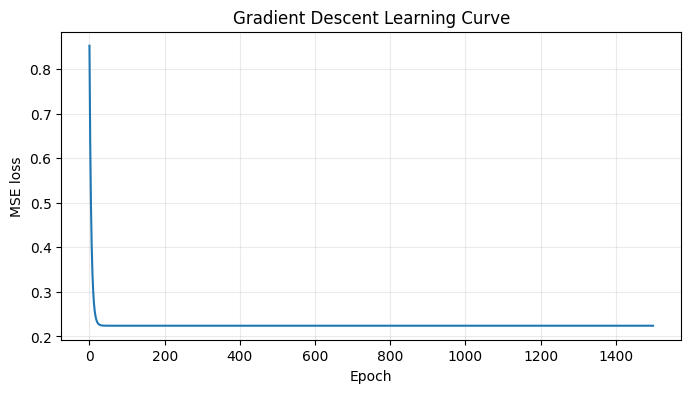

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Gradient Descent Learning Curve")
plt.grid(alpha=0.25)
plt.show()

## 6. Convert predictions back to the original Y scale

In [6]:
y_standard_pred = weight * x + bias
y_pred = y_standard_pred * std_y + mean_y

comparison = pd.DataFrame({
    "Actual": y_raw,
    "Predicted": y_pred
})
comparison.head(10)

,Actual,Predicted
0,30.0,45.424220
1,32.0,40.472249
2,37.0,42.579471
3,44.0,52.167330
4,47.0,59.015801
5,49.0,47.215359
6,56.0,61.860551
7,62.0,70.710883
8,68.0,60.596218
9,78.0,87.884741


## 7. Evaluate the trained model

In [7]:
errors = y_raw - y_pred
mse = np.mean(errors**2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(errors))

ss_res = np.sum(errors**2)
ss_tot = np.sum((y_raw - y_raw.mean())**2)
r2 = 1 - (ss_res / ss_tot)

print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"MAE  = {mae:.4f}")
print(f"R²   = {r2:.4f}")

MSE  = 437.1876
RMSE = 20.9090
MAE  = 16.1397
R²   = 0.7759


## 8. Show the learned regression line

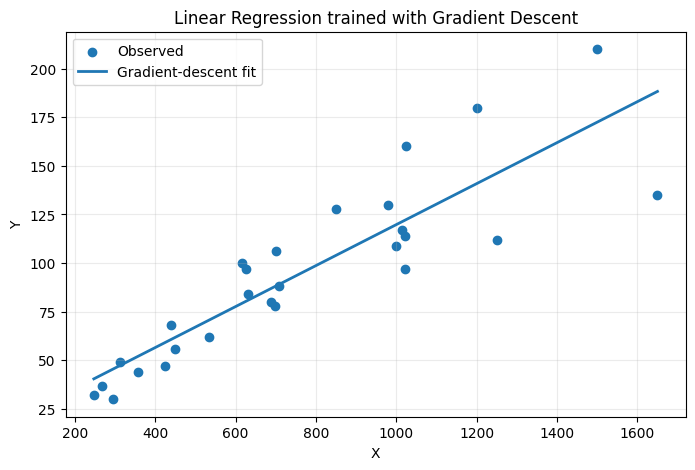

In [8]:
order = np.argsort(x_raw)
plt.figure(figsize=(8, 5))
plt.scatter(x_raw, y_raw, label="Observed")
plt.plot(x_raw[order], y_pred[order], linewidth=2, label="Gradient-descent fit")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression trained with Gradient Descent")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Conclusion
Gradient descent reaches a linear model by repeated parameter updates. The decreasing loss curve provides a visual check that the optimization is progressing toward a minimum.